In [1]:
from pathlib import Path
import geopandas as gpd
import rasterio
from rasterio.mask import mask
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rasterio.plot import show
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

In [2]:
# Admin boundaries
admin = gpd.read_file("admin/gadm41_PRT_0.shp")

# Multi polygons into polygons
admin = admin.explode(index_parts=False).reset_index(drop=True)

# Reproject to metric
admin_projected = admin.to_crs("EPSG:3763")

# Largest poly
largest_index = admin_projected.geometry.area.idxmax()

# Mainland Portugal
portugal = admin.loc[[largest_index]]

In [3]:
# Clip rasters
data_dir = Path("data")
output_dir = Path("clipped_tifs")
output_dir.mkdir(exist_ok=True)
raster_files = sorted(data_dir.rglob("kg_*.tif"))

for filename in raster_files:
    with rasterio.open(filename) as src:        
        boundary = portugal.to_crs(src.crs)        
        clipped, transform = mask(
            src,
            boundary.geometry,
            crop=True
        )

        # Update metadata
        metadata = src.meta.copy()
        metadata.update({
            "height": clipped.shape[1],
            "width": clipped.shape[2],
            "transform": transform
        })

        # Save clipped rasters
        output_file = output_dir / f"{filename.stem}_clipped.tif"
        with rasterio.open(output_file, "w", **metadata) as dst:
            dst.write(clipped)

In [4]:
# Clipped rasters
files = {
    "A": output_dir / "kg_9120_clipped.tif",
    "B": output_dir / "kg_4170_245_clipped.tif",
    "C": output_dir / "kg_4170_370_clipped.tif",
    "D": output_dir / "kg_4170_585_clipped.tif",
    "E": output_dir / "kg_7199_245_clipped.tif",
    "F": output_dir / "kg_7199_370_clipped.tif",
    "G": output_dir / "kg_7199_585_clipped.tif"
}

In [5]:
# Categories present in each raster
for name, filename in files.items():
    with rasterio.open(filename) as src:
        data = src.read(1, masked=True)
        # Unique pixel values w/o nodata
        categories = np.unique(data.compressed())
        print(name, categories)

A [8 9]
B [8 9]
C [8 9]
D [8 9]
E [8 9]
F [6 8 9]
G [6 8 9]


In [6]:
classes = {
    6: "BSh",
    8: "Csa",
    9: "Csb"
}

In [7]:
# Cmap
cmap = ListedColormap([
    "#C98D72",  # BSh
    "#D9C78F",  # Csa
    "#91B8AD",  # Csb
])

# Class boundaries
norm = BoundaryNorm([5.5, 7, 8.5, 9.5], cmap.N)

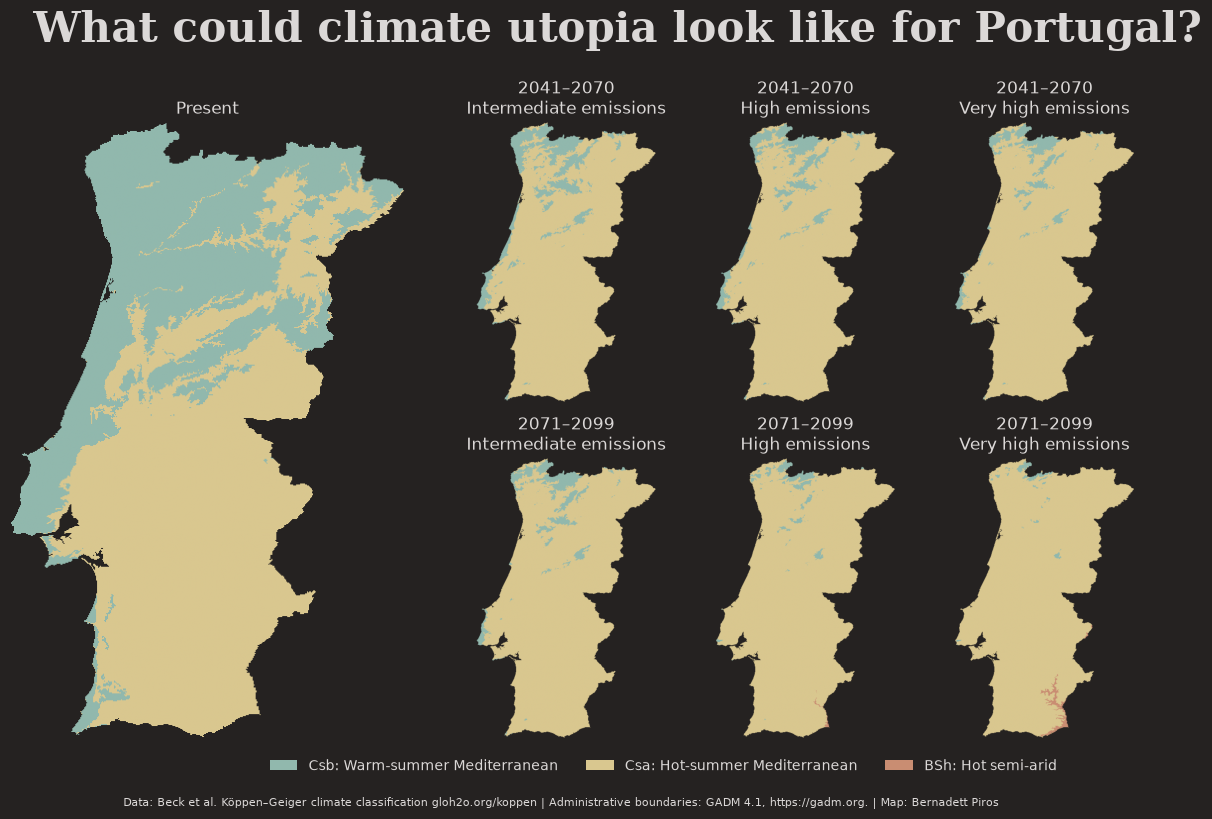

In [8]:
# Mosaic layout
layout = """
AABCD.
AAEFG.
"""

# Subplot titles
names = {
    "A": "Present",
    "B": "2041–2070\nIntermediate emissions",
    "C": "2041–2070\nHigh emissions",
    "D": "2041–2070\nVery high emissions",
    "E": "2071–2099\nIntermediate emissions",
    "F": "2071–2099\nHigh emissions",
    "G": "2071–2099\nVery high emissions"
}

fig, axes = plt.subplot_mosaic(layout, figsize=(18, 8), facecolor="#252221")

# Rasters
for name, filename in files.items():
    with rasterio.open(filename) as src:   
        
        ax = axes[name]
        title = names[name]
        
        show(src.read(1, masked=True), transform=src.transform, ax=ax, cmap=cmap, norm=norm)
        
        ax.set_title(title, color="#dbd8d7", fontfamily="sans-serif")

        ax.axis("off")

# Legend
legend_elements = [
    Patch(facecolor=cmap.colors[2], label="Csb: Warm-summer Mediterranean"),
    Patch(facecolor=cmap.colors[1], label="Csa: Hot-summer Mediterranean"),
    Patch(facecolor=cmap.colors[0], label="BSh: Hot semi-arid"),
]

fig.legend(handles=legend_elements, loc="lower center", ncol=3, frameon=False,
           prop={"family": "DejaVu Sans"},
           labelcolor="#dbd8d7", bbox_to_anchor=(0.5, 0.05))

# Title
fig.text(0.15, 0.98,
         "What could climate utopia look like for Portugal?",
         color="#dbd8d7", size=30, fontfamily="serif", weight="bold")

# Caption
fig.text(0.2, 0.025,
         "Data: Beck et al. Köppen–Geiger climate classification gloh2o.org/koppen | Administrative boundaries: GADM 4.1, https://gadm.org. | Map: Bernadett Piros",
         color="#dbd8d7", size=8)

plt.show()

# Save image
#plt.savefig("climate_utopia.png", bbox_inches="tight", pad_inches=0.2)